In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import copy
import seaborn as sns


In [2]:
df0404 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0404.csv")
df0712 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0712.csv")
df1703 = pd.read_csv("../data/labeledAndAnomaly/no_plug/1703.csv")
df2906_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/2906-1.csv")
df3006_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-1.csv")
df3006_2 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-2.csv")

df1103 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1103.csv")
df1803 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1803.csv")
df2503 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2503.csv")
df2108_1 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2108-1.csv")


df0612_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-2.csv")
df0612_3 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-3.csv")
df0707_1 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-1.csv")
df0707_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-2.csv")
df0707_4 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-4.csv")
df0709 = pd.read_csv("../data/labeledAndAnomaly/plug/0709.csv")
df1003 = pd.read_csv("../data/labeledAndAnomaly/plug/1003.csv")
df1112 = pd.read_csv("../data/labeledAndAnomaly/plug/1112.csv")
df1310_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-2.csv")
df1310_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-3.csv")
df1407_1 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-1.csv")
df1407_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-2.csv")
df1407_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-3.csv")
df1407_4 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-4.csv")
df1503 = pd.read_csv("../data/labeledAndAnomaly/plug/1503.csv")
df1811 = pd.read_csv("../data/labeledAndAnomaly/plug/1811.csv")
df2106_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2106-2.csv")
df2108_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2108-2.csv")
df2701 = pd.read_csv("../data/labeledAndAnomaly/plug/2701.csv")
df2906_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-2.csv")
df2906_3 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-3.csv")
df2906_4 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-4.csv")
df3006_3 = pd.read_csv("../data/labeledAndAnomaly/plug/3006-3.csv")

In [3]:
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
plug_dfs =  [df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, df1112, df1310_2, df1310_3,
            df1407_1, df1407_2, df1407_3, df1407_4, df1503, df1811, df2106_2, df2108_2, df2701, 
            df2906_2, df2906_3, df2906_4, df3006_3]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]

In [4]:
def prepare_phase_stratified_split(
    all_runs,
    feature_cols,
    window_size=60,
    train_ratio=0.60,
    val_ratio=0.20
):
    X_train_list, y_train_list, groups_train = [], [], []
    X_val_list, y_val_list, groups_val = [], [], []
    X_test_list, y_test_list, groups_test = [], [], []

    for run_id, df in enumerate(all_runs):
        # Ensure chronological order
        df_run = (
            df.sort_values('elapsed_runtime_s')
              .reset_index(drop=True)
              .copy()
        )

        # Identify contiguous state blocks
        df_run['state_block'] = (
            df_run['label'] != df_run['label'].shift(1)
        ).cumsum()

        # Process each state block separately
        for block_id, block in df_run.groupby('state_block'):
            block = block.reset_index(drop=True)

            n_samples = len(block)

            train_end = int(n_samples * train_ratio)
            val_end = int(n_samples * (train_ratio + val_ratio))

            # 60% / 20% / 20%
            train_block = block.iloc[:train_end]
            val_block = block.iloc[train_end:val_end]
            test_block = block.iloc[val_end:]

            # -------------------------
            # TRAIN WINDOWS
            # -------------------------
            train_vals = train_block[feature_cols].values
            train_labels = train_block['label'].values

            for i in range(window_size, len(train_vals)):
                X_train_list.append(
                    train_vals[i - window_size:i]
                )
                y_train_list.append(train_labels[i])
                groups_train.append(run_id)

            # -------------------------
            # VALIDATION WINDOWS
            # -------------------------
            val_vals = val_block[feature_cols].values
            val_labels = val_block['label'].values

            for i in range(window_size, len(val_vals)):
                X_val_list.append(
                    val_vals[i - window_size:i]
                )
                y_val_list.append(val_labels[i])
                groups_val.append(run_id)

            # -------------------------
            # TEST WINDOWS
            # -------------------------
            test_vals = test_block[feature_cols].values
            test_labels = test_block['label'].values

            for i in range(window_size, len(test_vals)):
                X_test_list.append(
                    test_vals[i - window_size:i]
                )
                y_test_list.append(test_labels[i])
                groups_test.append(run_id)

    X_train = np.array(X_train_list, dtype=np.float32)
    y_train = np.array(y_train_list, dtype=np.int64)

    X_val = np.array(X_val_list, dtype=np.float32)
    y_val = np.array(y_val_list, dtype=np.int64)

    X_test = np.array(X_test_list, dtype=np.float32)
    y_test = np.array(y_test_list, dtype=np.int64)

    return (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test,
        np.array(groups_train),
        np.array(groups_val),
        np.array(groups_test)
    )

In [5]:
all_runs = no_plug_dfs + plug_dfs + partial_plug_dfs

ORIGINAL_FEATURES = [
    'rel_tot_dp_change',
    'rel_ts_dp_change',
    'rel_p_ts_dp_change',
    'Relative_Ratio_Dev',
    'anomaly_score'
]

X_tr, y_tr, X_val, y_val, X_te, y_te, g_tr, g_val, g_te = (
    prepare_phase_stratified_split(
        all_runs=all_runs,
        feature_cols=ORIGINAL_FEATURES,
    )
)

print(f"Train Shapes: X={X_tr.shape}, y={y_tr.shape}")
print(f"Val Shapes:   X={X_val.shape}, y={y_val.shape}")
print(f"Test Shapes:  X={X_te.shape}, y={y_te.shape}")

Train Shapes: X=(94584, 60, 5), y=(94584,)
Val Shapes:   X=(29010, 60, 5), y=(29010,)
Test Shapes:  X=(29018, 60, 5), y=(29018,)


In [6]:
# Window-relative baseline subtraction
X_tr_zeroed = X_tr - X_tr[:, [0], :]
X_val_zeroed = X_val - X_val[:, [0], :]
X_te_zeroed = X_te - X_te[:, [0], :]

N_tr, S_tr, F_tr = X_tr_zeroed.shape

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_tr_zeroed.reshape(-1, F_tr)
).reshape(N_tr, S_tr, F_tr)

joblib.dump(scaler, '../models/zeroed_lstm_scaler.joblib')

['../models/plain_lstm_scaler.joblib']

In [8]:
X_val_scaled = scaler.transform(
    X_val_zeroed.reshape(-1, F_tr)
).reshape(*X_val_zeroed.shape)

X_test_scaled = scaler.transform(
    X_te_zeroed.reshape(-1, F_tr)
).reshape(*X_te_zeroed.shape)

In [9]:
# --- 4. Dataset & DataLoader ---
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [10]:
train_loader = DataLoader(
    SequenceDataset(X_train_scaled, y_tr),
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    SequenceDataset(X_val_scaled, y_val),
    batch_size=512,
    shuffle=False
)

test_loader = DataLoader(
    SequenceDataset(X_test_scaled, y_te),
    batch_size=512,
    shuffle=False
)

In [11]:
class PlainLSTM(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=64, num_layers=2, num_classes=4, dropout=0.3):
        super(PlainLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)           # [N, 60, hidden_dim]
        last_step = out[:, -1, :]       # [N, hidden_dim]
        return self.fc(last_step)

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = PlainLSTM(input_dim=F_tr, hidden_dim=64, num_layers=2, dropout=0.3).to(device)

In [13]:
# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)

# 3. Apply a modest boost to Class 3 to suppress Class 3 -> Class 0/1 leaks
class_weights[3] *= 1.2

# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

In [14]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [ ]:
# --- 6. Training Loop ---
EPOCHS = 40
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/zeroed_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'zeroed_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/40] | LR: 1.0e-03 | [TRAIN] Loss: 1.0518 | Acc: 41.44% [VALID] Loss: 0.8986 | Acc: 68.53%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [02/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.8301 | Acc: 65.30% [VALID] Loss: 0.8100 | Acc: 73.66%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [03/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.7367 | Acc: 70.20% [VALID] Loss: 0.7808 | Acc: 69.55%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [04/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6766 | Acc: 73.16% [VALID] Loss: 0.7118 | Acc: 74.22%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [05/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6313 | Acc: 75.13% [VALID] Loss: 0.6715 | Acc: 75.32%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [06/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.5780 | Acc: 78.29% [VALID] Loss: 0.6187 | Acc: 79.30%   New Best Val Loss! Weights saved to 'plain_lstm.pth'
Epoch [07/40] | LR: 1.0e-

In [ ]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/zeroed_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ BASELINE-SUBTRACTED TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ BASELINE-SUBTRACTED TEST BENCHMARK ================
Overall Accuracy: 87.92%

              precision    recall  f1-score   support

           0       0.95      0.89      0.92     15437
           1       0.53      0.68      0.59      2735
           2       0.92      0.95      0.93      9520
           3       0.72      0.73      0.72      1326

    accuracy                           0.88     29018
   macro avg       0.78      0.81      0.79     29018
weighted avg       0.89      0.88      0.88     29018



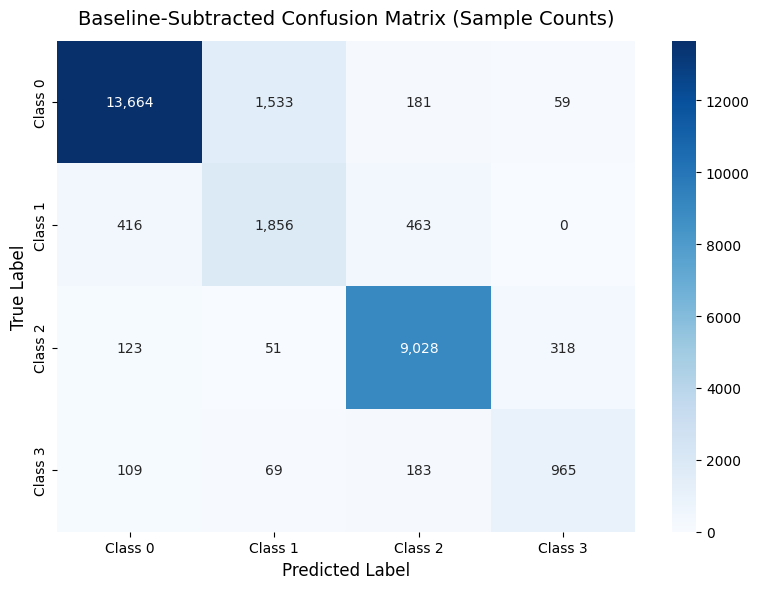

In [17]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Baseline-Subtracted Confusion Matrix (Sample Counts)', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = PlainLSTM(input_dim=F_tr, hidden_dim=64, num_layers=2, dropout=0.3).to(device)

# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)

# 3. Apply a modest boost to Class 3 to suppress Class 3 -> Class 0/1 leaks
class_weights[3] *= 1.3

# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [ ]:
# --- 6. Training Loop ---
EPOCHS = 40
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/zeroed1_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'zeroed1_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/40] | LR: 1.0e-03 | [TRAIN] Loss: 1.0362 | Acc: 44.34% [VALID] Loss: 1.0339 | Acc: 60.00%   New Best Val Loss! Weights saved to 'plain1_lstm.pth'
Epoch [02/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.7860 | Acc: 68.09% [VALID] Loss: 0.8238 | Acc: 71.29%   New Best Val Loss! Weights saved to 'plain1_lstm.pth'
Epoch [03/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6929 | Acc: 71.89% [VALID] Loss: 0.6786 | Acc: 75.77%   New Best Val Loss! Weights saved to 'plain1_lstm.pth'
Epoch [04/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6441 | Acc: 74.80% [VALID] Loss: 0.6093 | Acc: 76.83%   New Best Val Loss! Weights saved to 'plain1_lstm.pth'
Epoch [05/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.5991 | Acc: 76.65% [VALID] Loss: 0.6342 | Acc: 75.85%   [No Improvement (1/10)]
Epoch [06/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.5518 | Acc: 79.57% [VALID] Loss: 0.5782 | Acc: 78.66%   New Best Val Loss! Weights saved to 'plain1_lstm.pth'
Epoch [07/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.496

In [ ]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/zeroed1_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ BASELINE-SUBTRACTED TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ BASELINE-SUBTRACTED TEST BENCHMARK ================
Overall Accuracy: 86.14%

              precision    recall  f1-score   support

           0       0.96      0.87      0.91     15437
           1       0.53      0.68      0.60      2735
           2       0.90      0.91      0.91      9520
           3       0.56      0.80      0.66      1326

    accuracy                           0.86     29018
   macro avg       0.74      0.82      0.77     29018
weighted avg       0.88      0.86      0.87     29018



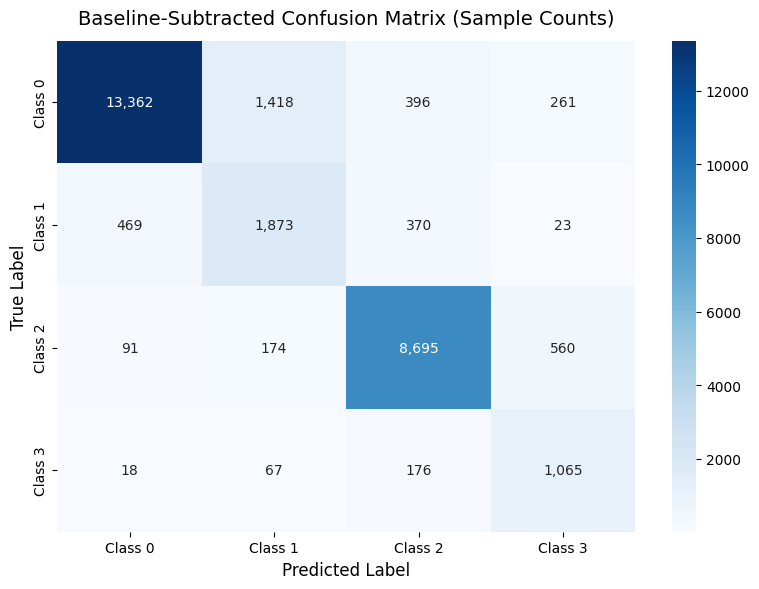

In [21]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Baseline-Subtracted Confusion Matrix (Sample Counts)', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [22]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = PlainLSTM(input_dim=F_tr, hidden_dim=64, num_layers=2, dropout=0.3).to(device)

# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)

# 3. Apply a modest boost to Class 3 to suppress Class 3 -> Class 0/1 leaks
class_weights[3] *= 1.1

# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [ ]:
# --- 6. Training Loop ---
EPOCHS = 40
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/zeroed2_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'zeroed2_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/40] | LR: 1.0e-03 | [TRAIN] Loss: 1.0533 | Acc: 41.49% [VALID] Loss: 1.0605 | Acc: 57.09%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [02/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.8372 | Acc: 64.53% [VALID] Loss: 0.8720 | Acc: 67.45%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [03/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.7491 | Acc: 70.51% [VALID] Loss: 0.7402 | Acc: 74.05%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [04/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6884 | Acc: 73.10% [VALID] Loss: 0.6794 | Acc: 78.17%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [05/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6367 | Acc: 75.90% [VALID] Loss: 0.6452 | Acc: 76.52%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [06/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6121 | Acc: 76.57% [VALID] Loss: 0.5861 | Acc: 80.64%   New Best Val Loss! Weights saved to 'plain3_lstm.pth'
Epoch [07/40] | LR:

In [ ]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/zeroed2_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ BASELINE-SUBTRACTED TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ BASELINE-SUBTRACTED TEST BENCHMARK ================
Overall Accuracy: 87.95%

              precision    recall  f1-score   support

           0       0.97      0.87      0.92     15437
           1       0.53      0.77      0.62      2735
           2       0.92      0.95      0.93      9520
           3       0.69      0.75      0.72      1326

    accuracy                           0.88     29018
   macro avg       0.78      0.83      0.80     29018
weighted avg       0.90      0.88      0.89     29018



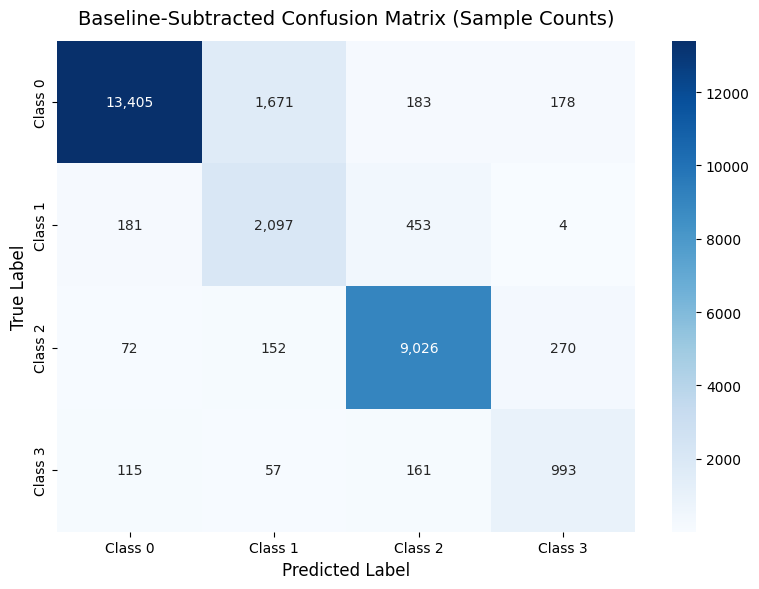

In [25]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Baseline-Subtracted Confusion Matrix (Sample Counts)', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [26]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = PlainLSTM(input_dim=F_tr, hidden_dim=64, num_layers=2, dropout=0.3).to(device)

# 1. Calculate class frequencies directly from y_tr
class_counts = np.bincount(y_tr)
total_samples = len(y_tr)

# 2. Compute balanced inverse weights
class_weights = total_samples / (len(class_counts) * class_counts)


# 4. Pass weights to loss function (moves to device automatically with model/data)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

In [ ]:
# --- 6. Training Loop ---
EPOCHS = 40
PATIENCE = 10
patience_counter = 0
best_val_loss = float('inf')

print(f"Training Baseline-Subtracted LSTM on {device}...\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)
        
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100

    scheduler.step(epoch_val_loss)

    # Check validation loss improvement
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), '../models/zeroed3_lstm.pth')
        patience_counter = 0  # Reset patience counter on improvement
        saved_msg = "   New Best Val Loss! Weights saved to 'zeroed3_lstm.pth'"
    else:
        patience_counter += 1
        saved_msg = f'   [No Improvement ({patience_counter}/{PATIENCE})]'

    current_lr = optimizer.param_groups[0]['lr']
    print(
      f'Epoch [{epoch:02d}/{EPOCHS:02d}] | LR: {current_lr:.1e} | [TRAIN]'
      f' Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% [VALID]'
      f' Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}%{saved_msg}'
    )

    # Early stopping trigger
    if patience_counter >= PATIENCE:
        print(
            f'\nEarly stopping triggered at Epoch {epoch}'
        )
        break

Training Baseline-Subtracted LSTM on cpu...

Epoch [01/40] | LR: 1.0e-03 | [TRAIN] Loss: 1.0508 | Acc: 43.04% [VALID] Loss: 0.9018 | Acc: 67.01%   New Best Val Loss! Weights saved to 'plain4_lstm.pth'
Epoch [02/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.8045 | Acc: 65.15% [VALID] Loss: 0.7537 | Acc: 71.61%   New Best Val Loss! Weights saved to 'plain4_lstm.pth'
Epoch [03/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.7064 | Acc: 72.27% [VALID] Loss: 0.7178 | Acc: 76.51%   New Best Val Loss! Weights saved to 'plain4_lstm.pth'
Epoch [04/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6461 | Acc: 75.11% [VALID] Loss: 0.6259 | Acc: 77.20%   New Best Val Loss! Weights saved to 'plain4_lstm.pth'
Epoch [05/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.6010 | Acc: 77.82% [VALID] Loss: 0.6086 | Acc: 78.83%   New Best Val Loss! Weights saved to 'plain4_lstm.pth'
Epoch [06/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.5351 | Acc: 80.31% [VALID] Loss: 0.6246 | Acc: 78.65%   [No Improvement (1/10)]
Epoch [07/40] | LR: 1.0e-03 | [TRAIN] Loss: 0.485

In [ ]:
# --- 7. Test Evaluation & Confusion Matrix ---
model.load_state_dict(torch.load('../models/zeroed3_lstm.pth', map_location=device))
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = torch.argmax(model(batch_X), dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.numpy())

print("\n================ BASELINE-SUBTRACTED TEST BENCHMARK ================")
print(f"Overall Accuracy: {accuracy_score(all_targets, all_preds) * 100:.2f}%\n")
print(classification_report(all_targets, all_preds, digits=2))


================ BASELINE-SUBTRACTED TEST BENCHMARK ================
Overall Accuracy: 85.30%

              precision    recall  f1-score   support

           0       0.95      0.83      0.88     15437
           1       0.52      0.76      0.62      2735
           2       0.91      0.92      0.92      9520
           3       0.57      0.82      0.67      1326

    accuracy                           0.85     29018
   macro avg       0.74      0.83      0.77     29018
weighted avg       0.88      0.85      0.86     29018



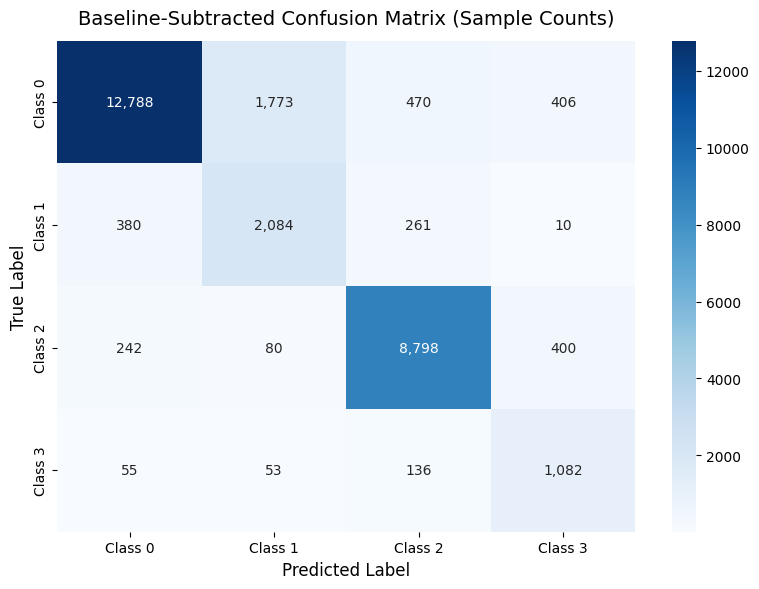

In [29]:
cm = confusion_matrix(all_targets, all_preds)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
plt.title('Baseline-Subtracted Confusion Matrix (Sample Counts)', fontsize=14, pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()